<a href="https://colab.research.google.com/github/JManuelRG/simuladores/blob/main/Destilacion/Simulador_McCabe_Thiele.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulador de destilación binaria — Método de McCabe-Thiele


**Antes de empezar**
1. Ejecuta las celdas en orden (menú *Entorno de ejecución → Ejecutar todo*).
2. Descarga en tu PC la base de Datos de Constantes de Antoine llamada: `Tabla Antoine.csv`  
La puedes descargar de este enlace: https://github.com/JManuelRG/simuladores/blob/main/Destilaci%C3%B3n/Tabla%20Antoine.csv

Cómo descargar:
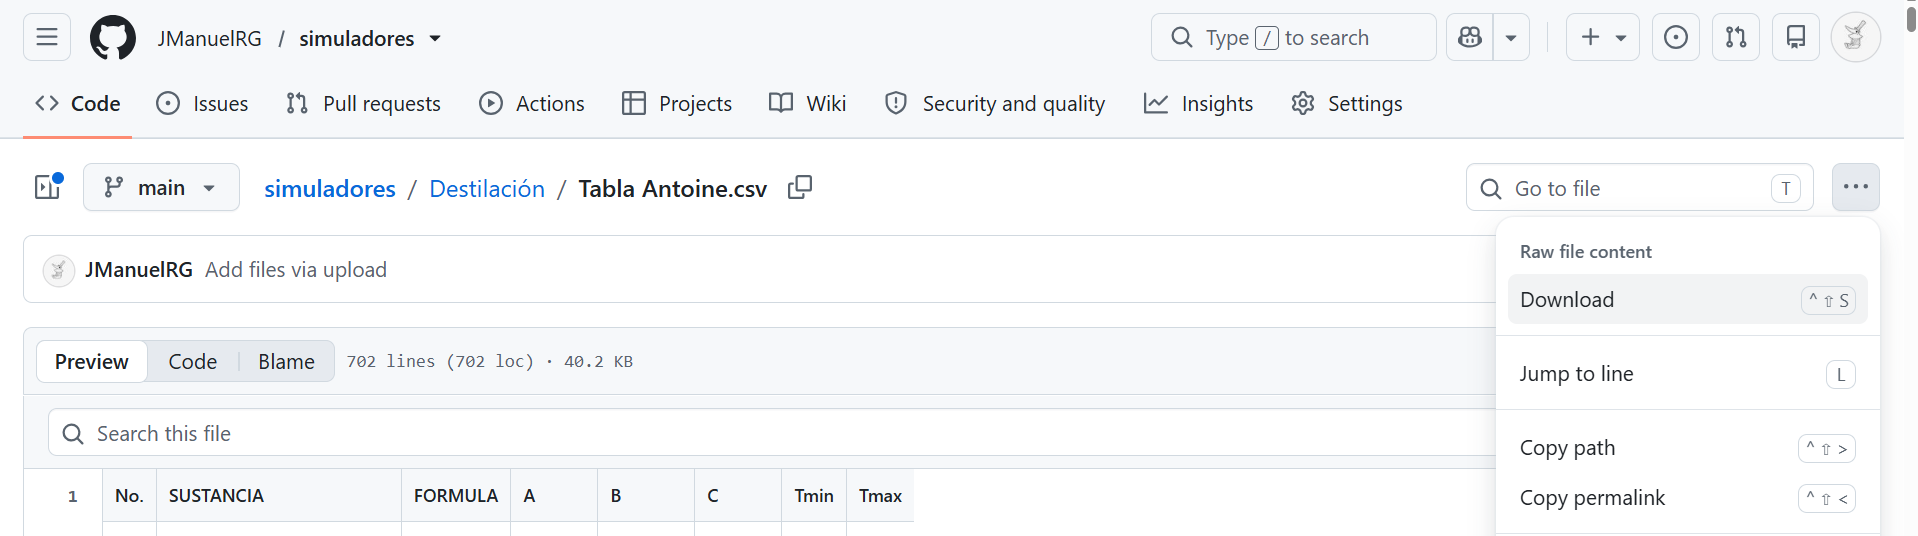

2. Teniendo descargada la base de Datos de Antoine, ejecuta la celda 1, solicitará subirla. Hacer click en el botón Elegir archivos. Navegar en su PC y elegir el archivo descargado.

3. Ejecuta la celda 2, para guardar la funciones de cálculo del programa.

4. Ejecuta la celda 3 para generar la interfaz gráfica, llena los datos correspondientes.

5. Usa la pestaña **Volatilidad relativa (Antoine)** si no conoces α, o ve directo a la pestaña **McCabe-Thiele** si ya la conoces.

Las constantes de Antoine se usan como en el original: `log10(Psat [mmHg]) = A − B / (T[°C] + C)`.

In [2]:
# Celda 1 · Librerías y base de datos de Antoine
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

RUTA_CSV = "Tabla Antoine.csv"
if not os.path.exists(RUTA_CSV):
    from google.colab import files
    print("Sube el archivo 'Tabla Antoine.csv'")
    subido = files.upload()
    RUTA_CSV = RUTA_CSV if RUTA_CSV in subido else next(iter(subido))

tablaAntoine = pd.read_csv(RUTA_CSV, index_col="SUSTANCIA")
tablaAntoine = tablaAntoine.drop(['No.'], axis=1)
print(f"Base de datos cargada: {len(tablaAntoine)} sustancias")


Sube el archivo 'Tabla Antoine.csv'


Saving Tabla Antoine.csv to Tabla Antoine.csv
Base de datos cargada: 701 sustancias


In [3]:
# Celda 2 · Funciones de cálculo y gráfico (método de McCabe-Thiele)
import numpy as np
import matplotlib.pyplot as plt

def curva_equilibrio(a):
    x_eq = np.linspace(0, 1, 51)
    y_eq = a * x_eq / (1 + (a - 1) * x_eq)
    return y_eq, x_eq

def linea_alimentacion(xF, q, a):
    c1 = q * (a - 1)
    c2 = q + xF * (1 - a) - a * (q - 1)
    c3 = -xF
    r = np.sort(np.roots([c1, c2, c3]))
    xiE = r[0] if r[0] > 0 else r[1]
    yiE = a * xiE / (1 + xiE * (a - 1))
    if q == 1:
        x_fed = np.array([xF, xF])
        y_fed = np.array([xF, yiE])
    else:
        x_fed = np.linspace(xF, xiE, 51)
        y_fed = q / (q - 1) * x_fed - xF / (q - 1)
    return xiE, yiE, y_fed, x_fed

def mccabe_thiele(xF, xD, xW, R, a, q, guardar_png=True):
    """R se interpreta como múltiplo de Rmin (R = R * Rmin), igual que en el original."""
    if not (0 < xW < xF < xD < 1):
        raise ValueError("Se requiere 0 < xW < xF < xD < 1")
    if a <= 1:
        raise ValueError("La volatilidad relativa (a) debe ser mayor que 1")

    y_eq, x_eq = curva_equilibrio(a)
    xiE, yiE, y_fed, x_fed = linea_alimentacion(xF, q, a)

    R_min = (xD - yiE) / (yiE - xiE)
    R = R * R_min

    # Punto de intersección de las líneas de operación
    if q == 1:
        xiF = xF
    else:
        xiF = (xF / (q - 1) + xD / (R + 1)) / (q / (q - 1) - R / (R + 1))
    yiF = R / (R + 1) * xiF + xD / (R + 1)

    # Sección de rectificación
    x_rect = np.linspace(xiF - 0.025, xD, 51)
    y_rect = R / (R + 1) * x_rect + xD / (R + 1)
    # Sección de agotamiento
    x_stp = np.linspace(xW, xiF + 0.025, 51)
    y_stp = ((yiF - xW) / (xiF - xW)) * (x_stp - xW) + xW

    # Construcción de etapas
    s = np.zeros((1000, 5))
    s[0, 0] = xD
    s[0, 1] = xD
    s[0, 2] = s[0, 1] / (a - s[0, 1] * (a - 1))
    s[0, 3] = s[0, 1]
    s[0, 4] = 0
    for i in range(1, 1000):
        s[i, 0] = s[i - 1, 2]
        if s[i, 0] < xW:
            s[i, 1] = s[i, 0]
            s[i, 2] = s[i, 0]
            s[i, 3] = s[i, 0]
            s[i, 4] = i
            break
        if s[i, 0] > xiF:
            s[i, 1] = R / (R + 1) * s[i, 0] + xD / (R + 1)
        elif s[i, 0] < xiF:
            s[i, 1] = ((yiF - xW) / (xiF - xW)) * (s[i, 0] - xW) + xW
        else:
            s[i, 1] = s[i - 1, 3]
        if s[i, 0] > xW:
            s[i, 2] = s[i, 1] / (a - s[i, 1] * (a - 1))
        else:
            s[i, 2] = s[i, 0]
        s[i, 3] = s[i, 1]
        s[i, 4] = i if s[i, 0] < xiF else 0
    s = s[~np.all(s == 0, axis=1)]
    s_rows = s.shape[0]
    S = np.zeros((s_rows * 2, 2))
    for i in range(s_rows):
        S[i * 2, 0] = s[i, 0]
        S[i * 2, 1] = s[i, 1]
        S[i * 2 + 1, 0] = s[i, 2]
        S[i * 2 + 1, 1] = s[i, 3]

    x_s = s[:, 2]
    y_s = s[:, 3]
    stage = [str(k) for k in range(1, s_rows)]
    s_f = int(s_rows - np.count_nonzero(s[:, 4]))
    n_etapas = s_rows - 1

    # Gráfico
    fig = plt.figure(figsize=(10, 4.2), dpi=110)
    plt.plot([0, 1], [0, 1], "k-")
    plt.plot(x_eq, y_eq, "r-", label="Curva de equilibrio")
    plt.plot(x_rect, y_rect, "k--", label="Sección de rectificación")
    plt.plot(x_stp, y_stp, "k-.", label="Sección de agotamiento")
    plt.plot(x_fed, y_fed, "k:", label="Plato de alimentación")
    plt.plot(S[:, 0], S[:, 1], "b-", label="Etapas")
    plt.plot([xF, xF], [0, xF], color="lawngreen")
    plt.plot([xW, xW], [0, xW], color="indigo")
    plt.plot([xD, xD], [0, xD], color="deepskyblue")
    for label, x, y in zip(stage, x_s, y_s):
        plt.annotate(label, xy=(x, y), xytext=(0, 5),
                     textcoords="offset points", ha="right")
    plt.plot(xF, xF, "go", xD, xD, "go", xW, xW, "go", markersize=5)
    plt.text(xF + 0.05, xF - 0.03, "($x_{F}, x_{F}$)", horizontalalignment="center")
    plt.text(xD + 0.05, xD - 0.03, "($x_{D}, x_{D}$)", horizontalalignment="center")
    plt.text(xW + 0.05, xW - 0.03, "($x_{W}, x_{W}$)", horizontalalignment="center")
    plt.plot(xiF, yiF, "go", markersize=5)
    plt.text(xiF + 0.05, yiF - 0.05, "($x_{iF}, y_{iF}$)", horizontalalignment="center")
    textstr1 = "\n".join((
        r"$Entradas:$",
        r"$\alpha=%.1f$" % (a,),
        r"$q=%.2f$" % (q,),
        r"$x_F=%.2f$" % (xF,),
        r"$x_D=%.2f$" % (xD,),
        r"$x_W=%.2f$" % (xW,)))
    textstr2 = "\n".join((
        r"$Salidas:$",
        r"$R_{min}=%.2f$" % (R_min,),
        r"$R=%.2f$" % (R,),
        r"$Etapas=%.0f$" % (n_etapas,),
        r"$Plato\: de \:alimentación=%.0f$" % (s_f,)))
    props = dict(boxstyle="round", facecolor="wheat", alpha=0.5)
    plt.text(0.65, 0.33, textstr1, fontsize=8, verticalalignment="bottom", bbox=props)
    plt.text(0.65, 0.0, textstr2, fontsize=8, verticalalignment="bottom", bbox=props)
    plt.grid(True, which="major", linestyle=":", alpha=0.6)
    plt.grid(True, which="minor", linestyle=":", alpha=0.3)
    plt.minorticks_on()
    plt.legend(loc="upper left", shadow=True)
    plt.xlabel("Composición en la fase L, x")
    plt.ylabel("Composición en la fase V, y")
    plt.title("Destilación Binaria : Método de McCabe - Thiele")
    if guardar_png:
        plt.savefig("McCabe - Thiele Method.png", dpi=140)
    return dict(fig=fig, R_min=R_min, R=R, etapas=n_etapas, plato_alim=s_f)


In [4]:
# Celda 3 · Interfaz (pestañas)
estilo = {"description_width": "150px"}
lay = widgets.Layout(width="420px")

# ---------------- Pestaña 1: Volatilidad relativa (Antoine) ----------------
opciones = [(f"{fila['FORMULA']}  {sust}", sust) for sust, fila in tablaAntoine.iterrows()]

menucomp1 = widgets.Dropdown(options=opciones, value=None, description="Componente 1:", style=estilo, layout=lay)
menucomp2 = widgets.Dropdown(options=opciones, value=None, description="Componente 2:", style=estilo, layout=lay)
antoinec1 = widgets.HTML("<pre>Constantes de Antoine:\nA=\nB=\nC=</pre>")
antoinec2 = widgets.HTML("<pre>Constantes de Antoine:\nA=\nB=\nC=</pre>")
cajaT = widgets.Text(description="Temperatura (°C):", style=estilo, layout=lay)
lblP1 = widgets.HTML("<b>Psat 1 =</b>")
lblP2 = widgets.HTML("<b>Psat 2 =</b>")
lblVol = widgets.HTML("<b>Volatilidad calculada:</b>")
msg_vol = widgets.HTML("")
alfa_calculada = {"valor": None}

btn_calcvol = widgets.Button(description="Calcular Volatilidad", button_style="primary", layout=widgets.Layout(width="190px"))
btn_limpiarv = widgets.Button(description="Limpiar Datos", layout=widgets.Layout(width="190px"))
btn_usar_alfa = widgets.Button(description="Usar α en McCabe-Thiele", button_style="success",
                               disabled=True, layout=widgets.Layout(width="230px"))

def calcvol(_=None):
    msg_vol.value = ""
    try:
        T = float(cajaT.value)
        if menucomp1.value is None or menucomp2.value is None:
            raise IndexError
        ctes1 = tablaAntoine.loc[menucomp1.value]
        ctes2 = tablaAntoine.loc[menucomp2.value]
        antoinec1.value = f"<pre>{ctes1.to_string()}</pre>"
        antoinec2.value = f"<pre>{ctes2.to_string()}</pre>"

        # Constantes de Antoine (posiciones 1, 2, 3 = A, B, C, igual que el original)
        A1, B1, C1 = ctes1.iloc[1], ctes1.iloc[2], ctes1.iloc[3]
        A2, B2, C2 = ctes2.iloc[1], ctes2.iloc[2], ctes2.iloc[3]

        Psat1 = 10 ** (A1 - B1 / (T + C1))
        Psat2 = 10 ** (A2 - B2 / (T + C2))
        valoralfa = Psat1 / Psat2

        lblVol.value = f"<b>Volatilidad calculada:</b> {round(valoralfa, 6)}"
        lblP1.value = f"<b>Psat 1 =</b> {round(Psat1, 6)} mmHg"
        lblP2.value = f"<b>Psat 2 =</b> {round(Psat2, 6)} mmHg"
        alfa_calculada["valor"] = valoralfa
        btn_usar_alfa.disabled = False
    except KeyError:
        msg_vol.value = "<span style='color:#b00'>Verifique los compuestos introducidos</span>"
    except ValueError:
        msg_vol.value = "<span style='color:#b00'>Revisa el valor de temperatura introducido</span>"
    except IndexError:
        msg_vol.value = "<span style='color:#b00'>Ingresa ambos componentes</span>"
    except ZeroDivisionError:
        msg_vol.value = "<span style='color:#b00'>T + C = 0: revisa la temperatura</span>"

def limpiarv(_=None):
    cajaT.value = ""
    menucomp1.value = None
    menucomp2.value = None
    antoinec1.value = "<pre>Constantes de Antoine:\nA=\nB=\nC=</pre>"
    antoinec2.value = "<pre>Constantes de Antoine:\nA=\nB=\nC=</pre>"
    lblVol.value = "<b>Volatilidad calculada:</b>"
    lblP1.value = "<b>Psat 1 =</b>"
    lblP2.value = "<b>Psat 2 =</b>"
    msg_vol.value = ""
    alfa_calculada["valor"] = None
    btn_usar_alfa.disabled = True

btn_calcvol.on_click(calcvol)
btn_limpiarv.on_click(limpiarv)

tab_antoine = widgets.VBox([
    widgets.HTML("<h3>Volatilidad relativa de la mezcla</h3>"),
    menucomp1, antoinec1,
    menucomp2, antoinec2,
    widgets.HTML("<b>Condiciones de la mezcla</b>"),
    cajaT, lblP1, lblP2, lblVol,
    widgets.HBox([btn_calcvol, btn_limpiarv, btn_usar_alfa]),
    msg_vol,
])

# ---------------- Pestaña 2: McCabe-Thiele ----------------
est2 = {"description_width": "230px"}
lay2 = widgets.Layout(width="420px")
cajaxf = widgets.Text(description="xF (alimentación):", placeholder="ej. 0.35", style=est2, layout=lay2)
cajaxd = widgets.Text(description="xD (destilado):", placeholder="ej. 0.975", style=est2, layout=lay2)
cajaxw = widgets.Text(description="xW (fondos):", placeholder="ej. 0.025", style=est2, layout=lay2)
cajar = widgets.Text(description="R / Rmin (múltiplo de Rmin):", placeholder="ej. 1.5", style=est2, layout=lay2)
cajaa = widgets.Text(description="a (volatilidad relativa):", placeholder="ej. 2.5", style=est2, layout=lay2)
cajaq = widgets.Text(description="q (cond. de alimentación):", placeholder="ej. 1.5", style=est2, layout=lay2)

estado = widgets.HTML("Ingresa las variables de tu mezcla")
res_Rmin = widgets.HTML("<b>Rmin:</b>")
res_R = widgets.HTML("<b>R:</b>")
res_et = widgets.HTML("<b>Etapas:</b>")
res_pf = widgets.HTML("<b>Plato de alimentación:</b>")
out_graf = widgets.Output()

btn_calc = widgets.Button(description="Registrar los datos", button_style="primary", layout=widgets.Layout(width="190px"))
btn_limpiar = widgets.Button(description="Limpiar Datos", layout=widgets.Layout(width="190px"))
btn_png = widgets.Button(description="Descargar gráfica (PNG)", disabled=True, layout=widgets.Layout(width="220px"))

def calcular(_=None):
    try:
        xF = float(cajaxf.value); xD = float(cajaxd.value); xW = float(cajaxw.value)
        R = float(cajar.value); a = float(cajaa.value); q = float(cajaq.value)
    except ValueError:
        estado.value = "<span style='color:#b00'>Revisa que todos los campos sean números</span>"
        return
    try:
        res = mccabe_thiele(xF, xD, xW, R, a, q)
    except Exception as e:
        estado.value = f"<span style='color:#b00'>{e}</span>"
        return
    estado.value = "Los datos han sido ingresados"
    res_Rmin.value = f"<b>Rmin:</b> {res['R_min']:.4f}"
    res_R.value = f"<b>R:</b> {res['R']:.4f}"
    res_et.value = f"<b>Etapas:</b> {res['etapas']}"
    res_pf.value = f"<b>Plato de alimentación:</b> {res['plato_alim']}"
    with out_graf:
        clear_output(wait=True)
        plt.show()
    plt.close(res["fig"])
    btn_png.disabled = False

def limpiar(_=None):
    for c in (cajaxf, cajaxd, cajaxw, cajar, cajaa, cajaq):
        c.value = ""
    estado.value = "Ingresa las variables de tu mezcla"
    res_Rmin.value = "<b>Rmin:</b>"
    res_R.value = "<b>R:</b>"
    res_et.value = "<b>Etapas:</b>"
    res_pf.value = "<b>Plato de alimentación:</b>"
    btn_png.disabled = True
    with out_graf:
        clear_output()

def descargar(_=None):
    try:
        from google.colab import files
        files.download("McCabe - Thiele Method.png")
    except Exception:
        estado.value = "La gráfica quedó guardada como 'McCabe - Thiele Method.png' en el panel de archivos"

btn_calc.on_click(calcular)
btn_limpiar.on_click(limpiar)
btn_png.on_click(descargar)

def usar_alfa(_=None):
    if alfa_calculada["valor"] is not None:
        cajaa.value = str(round(alfa_calculada["valor"], 6))
        tabs.selected_index = 1

btn_usar_alfa.on_click(usar_alfa)

tab_mt = widgets.VBox([
    widgets.HTML("<h3>Entradas</h3>"), estado,
    cajaxf, cajaxd, cajaxw, cajar, cajaa, cajaq,
    widgets.HBox([btn_calc, btn_limpiar, btn_png]),
    widgets.HTML("<h3>Resultados</h3>"),
    res_Rmin, res_R, res_et, res_pf,
    widgets.HTML("<h3>Gráfico generado</h3>"), out_graf,
])

tabs = widgets.Tab(children=[tab_antoine, tab_mt])
tabs.set_title(0, "Volatilidad relativa (Antoine)")
tabs.set_title(1, "McCabe-Thiele")
display(tabs)
